In [3]:
import pandas as pd
import json

In [2]:
JSON_PATH = r"C:\Users\lunaf\Desktop\Projects\geographic-information-system-analyzer\data\raw\kadıköy_amenity_20251013_142310.json"

In [9]:
with open(JSON_PATH, 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

In [10]:
df_data = pd.json_normalize(raw_data, record_path=['data'], meta=['area', 'tag', 'count'])

In [12]:
df_data[df_data["type"] == "bar"].head()

,id,name,type,lat,lon,tags.addr:floor,tags.amenity,tags.check_date,tags.ferry,tags.level,...,tags.organic,tags.payment:contactless,tags.instagram,tags.drink:beer,tags.recycling:glass,tags.recycling:plastic_bottles,tags.community:gender,area,tag,count
41,1921444719,None,bar,41.0114442,29.0383269,NaN,bar,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Kadıköy,amenity,3291
58,2433366996,Fil,bar,40.9872396,29.0277667,NaN,bar,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Kadıköy,amenity,3291
73,2433671835,Arkaoda,bar,40.9865900,29.0265392,NaN,bar,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Kadıköy,amenity,3291
153,2450051798,Kadife,bar,40.9872032,29.0268261,NaN,bar,2024-11-01,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Kadıköy,amenity,3291
296,4224524796,SCHLEPP Cafe & Pub,bar,40.9909532,29.0306204,NaN,bar,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Kadıköy,amenity,3291


In [28]:
df_data.shape

(3291, 241)

In [32]:
main_df = df_data[["id", "name", "type", "lat", "lon", "area", "tag"]]

In [33]:
main_df.head()

,id,name,type,lat,lon,area,tag
0,409151054,Şehir hatları Karaköy Eminönü İskelesi,ferry_terminal,40.9930645,29.0225349,Kadıköy,amenity
1,583523020,Kadiköy,ferry_terminal,40.9918235,29.0215476,Kadıköy,amenity
2,769894567,None,taxi,41.0120851,29.0369929,Kadıköy,amenity
3,769895246,Kosuyolu Saglik Ocagi,clinic,41.0075838,29.0358127,Kadıköy,amenity
4,769896040,PTT Koşuyolu,post_office,41.0082997,29.0367119,Kadıköy,amenity


In [35]:
type_list = main_df["type"].values

In [42]:
set(type_list)

{'arts_centre',
 'atm',
 'bank',
 'bar',
 'bench',
 'bicycle_parking',
 'bicycle_rental',
 'bicycle_repair_station',
 'bureau_de_change',
 'bus_station',
 'cafe',
 'car_rental',
 'car_sharing',
 'car_wash',
 'charging_station',
 'childcare',
 'cinema',
 'clinic',
 'clock',
 'community_centre',
 'dancing_school',
 'dentist',
 'doctors',
 'drinking_water',
 'driving_school',
 'events_venue',
 'fast_food',
 'ferry_terminal',
 'food_court',
 'fountain',
 'fuel',
 'healthcare',
 'hospital',
 'ice_cream',
 'internet_cafe',
 'kindergarten',
 'language_school',
 'library',
 'marketplace',
 'music_school',
 'nightclub',
 'notary',
 'parcel_locker',
 'parking',
 'parking_entrance',
 'payment_centre',
 'pharmacy',
 'place_of_worship',
 'police',
 'post_office',
 'pub',
 'recycling',
 'restaurant',
 'school',
 'shelter',
 'shower',
 'social_club',
 'social_facility',
 'studio',
 'taxi',
 'telephone',
 'theatre',
 'ticket_validator',
 'toilets',
 'townhall',
 'vending_machine',
 'veterinary',
 'was

In [43]:
len(set(type_list))

71

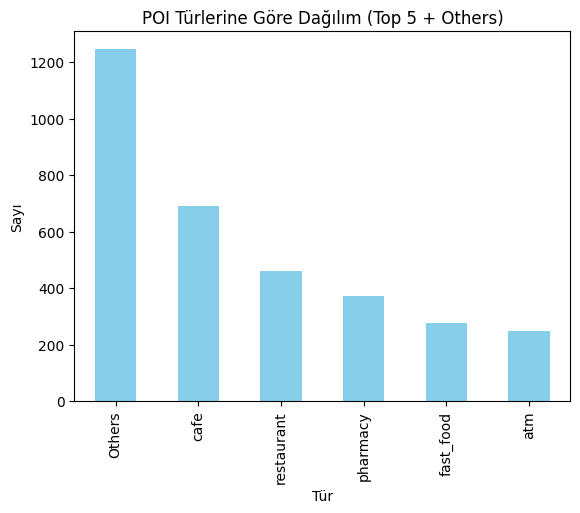

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# type sütununu say ve sırala
top_n = 5
type_counts = main_df['type'].value_counts()

# Top 5 tür
top_types = type_counts.nlargest(top_n).index.tolist()

# Yeni sütun oluştur: Top5 dışında Others
main_df['type_grouped'] = main_df['type'].apply(lambda x: x if x in top_types else 'Others')

# Bar chart
main_df['type_grouped'].value_counts().plot(kind='bar', color='skyblue')
plt.title("POI Türlerine Göre Dağılım (Top 5 + Others)")
plt.xlabel("Tür")
plt.ylabel("Sayı")
plt.show()

In [ ]:
plt.scatter(main_df["lon"], main_df["lat"], c="blue", alpha=0.6)
plt.title("POI Konum Dağılımı")
plt.xlabel("Boylam (lon)")
plt.ylabel("Enlem (lat)")
plt.show()